# Related Papers:
- https://aclanthology.org/2024.acl-short.2.pdf
- https://aclanthology.org/2024.emnlp-main.171.pdf
- https://arxiv.org/pdf/2408.09174v1
- https://aclanthology.org/2025.findings-emnlp.638.pdf
- https://aclanthology.org/2025.emnlp-main.363.pdf

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

In [2]:
import json

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)

def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

# TODO:
1. Wikipedia harvest - Run as is for now, try to understand why it crushes near the end. **---------> DONE!**
2. Extract tables:
    - length between 3 to 10 **---------> DONE!**
    - table is square and parsed normally (no merged cells) **---------> DONE!**
    - full table **---------> DONE!**
    - remove some columns with no relevant data (empty or by keywords) **---------> DONE!**
3. Add to table extraction text titles and relevant paragraphs for the context. **---------> DONE!**
4. Cluster titles to remove similar options + take only one table per page. **---------> DONE!**
5. Create groups - all the table, try to see what is the main entity - return the column name, if they don't have one, discard the table and return 'None'. **---------> DONE!**
6. Create Questions
    - strategy injection, sample a subset of strategies in a shuffled order, if not possible than discard table.
    - make a function to extract the answer per question strategy --> create GT answer.
    - Add the 'group size' strategy.
    - constract the data samples.

### Havest Wikipedia pages with tables:

In [91]:
from knowledge_maze.create_dataset.create_questions.wikipedia_mining import WikiHarvester
# Initialize Wikipedia harvester
harvester = WikiHarvester()
# Run Phase 1 - Harvesting titles based on keywords
harvester.run_complete_harvest()
# Run Phase 2 - Filtering pages for tables
await harvester.filter_pages_async()

Harvesting Pages By Keywords:   0%|          | 0/233 [00:00<?, ?keyword/s]


TOTAL UNIQUE TITLES COLLECTED: 167913



Method,Keyword,Count
Prefix,List of cities,1537
Prefix,List of countries,1278
Prefix,List of towns,501
Prefix,List of villages,483
Prefix,List of districts,375
Prefix,List of municipalities,1021
Prefix,List of communes,194
Prefix,List of counties,259
Prefix,List of provinces,84
Prefix,List of territories,22


Filtering Pages with Tables:   0%|          | 0/167913 [00:00<?, ?page/s]


TOTAL PAGES WITH TABLES COLLECTED: 62306



In [93]:
save_json("table_titles", harvester.valid_titles)

In [3]:
table_titles = load_json("C:/Users/Daniel/Desktop/KnowledgeMaze/data_files/table_titles.json")

### Parse and filter Wikipedia tables:

In [271]:
from knowledge_maze.create_dataset.create_questions.table_processing import AsyncWikiExtractor, TablePostProcessor

extractor = AsyncWikiExtractor(output_file=os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
validated_tables_file_name = await extractor.run_with_progress(table_titles)
validated_tables = load_jsonl(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))

processor = TablePostProcessor(os.path.join(REPO_PATH, "data_files/final_tables.jsonl"))
cleaned_data = processor.process()

Pre-processing: cluster similar pages and discard similarities ---> 6426 pages discarded.


Extracting Tables:   0%|          | 0/55880 [00:00<?, ?Page/s]

Starting Extraction: 55880 titles | Async Limit: 20 | CPU Workers: 19
TOTAL PAGES WITH VALID TABLES: 32076 OUT OF 55880 (57.4%)


Filtering & Cleaning:   0%|          | 0/94101 [00:00<?, ?it/s]


════════════════════════════════════════════
📊 TABLE PROCESSING SUMMARY (Limit: 12)
════════════════════════════════════════════
Total tables scanned:      94101
Dropped (Bad Headers):     8435
Dropped (Cell too long):   2841
Dropped (Repeat Rows):     1783
Short tables found:        39837
Unique source pages:       16940
Final sampled (1/page):    16940
════════════════════════════════════════════

------------------------------------------------------------------------------------------------------------------------------------------------------
                                                                  ↓ EXAMPLE TABLES ↓                                                                  
------------------------------------------------------------------------------------------------------------------------------------------------------

══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════

,Rank,Player,Career,Caps,Goals
0,1,Christine Sinclair,2000–2023,331,190
1,2,Sophie Schmidt,2005–2023,226,20
2,3,Diana Matheson,2003–2021,206,19
3,4,Desiree Scott,2010–2025,188,0
4,5,Rhian Wilkinson,2003–2017,181,7
5,6,Kadeisha Buchanan,2013–present,154,6
6,7,Ashley Lawrence,2013–present,151,8
7,7,Jessie Fleming,2013–present,151,20
8,9,Brittany Baxter,2002–2014,132,5
9,9,Andrea Neil,1991–2007,132,24



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
Manchester City F.C. 3–2 Queens Park Rangers F.C. > Match > Statistics
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Statistic,Manchester City,Queens Park Rangers
0,Goals scored,3,2
1,Possession,81.3%,18.7%
2,Shots on target,15,3
3,Shots off target,10,0
4,Blocked shots,19,0
5,Corner kicks,19,0
6,Fouls,4,7
7,Tackles,15,22
8,Offsides,1,1
9,Yellow cards,2,1



══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
Swinburne University of Technology > Notable people > Academics and staff
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════


,Member,Executive team,Period
0,Pascale Quester,Vice-Chancellor,2020–present
1,Chris Pilgrim,Pro Vice-Chancellor (Academic),
2,Tara Magdalinski,Pro Vice-Chancellor (Education and Quality),
3,Sarah Maddison,Pro Vice-Chancellor (Academic Innovation and C...,
4,Bronwyn Fox,Deputy Vice-Chancellor (Research and Enterprise),
5,Beth Webster,Pro Vice-Chancellor (Research Policy and Impact),
6,Qing-Lon Han,Pro Vice-Chancellor (Research Quality),
7,Alan Kin-Tak Lau,Pro Vice-Chancellor (International Research De...,
8,Blair Kuys,Dean of the School of Design and Architecture,
9,Matthew Bailes,Director of the Data Science Research Institut...,


### Create Potential Entity Groups:

In [7]:
from knowledge_maze.create_dataset.create_questions.grouping_entities import TableGroupConstructor

group_constructor = TableGroupConstructor(random.sample(cleaned_data, 1000))
await group_constructor.get_groups()

🚀 Grouping 1000 tables using Entity-Focus logic...


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/1000 [00:00<?, ?it/s]


════════════════════════════════════════════════════════════════════════════════
                               📊 GROUPING REPORT                                
════════════════════════════════════════════════════════════════════════════════
  ✅ Valid Groups:   864
  ❌ Invalid Tables: 136
════════════════════════════════════════════════════════════════════════════════

✨ SAMPLE VALID NAMES:
  → Ports and harbours in Tanzania
  → Chart performance for Carver City in 2009
  → Filmfare Awards received by Atif Aslam

────────────────────────────────────────────────────────────────────────────────
                     🕵️ REJECTION DEBUGGER (Random Sample)                      
────────────────────────────────────────────────────────────────────────────────

[TABLE]: Mesa Grande Band of Diegueno Mission Indians > Reservation > Demographics (Mesa Grande Reservation, California – Racial and ethnic composition Note: the US Census treats Hispanic/Latino as an ethnic category. This table exclud

In [12]:
for sample in random.sample(group_constructor.valid_tables, 25):
    print(f"Group name: {sample['Group name']}")
    print(f"Wikipedia page: {sample['Wikipedia link']}")
    print(f"Entity column: {sample['Entity column']}")
    display(pd.DataFrame(sample['Table data']))
    print()
    print()

Group name: Rankings of Steve Williams in the 200 meters
Wikipedia page: https://en.wikipedia.org/wiki/Steve_Williams_(sprinter)#Rankings
Entity column: Year


,Year,World rank,US rank
0,1972,-,6th
1,1973,1st,1st
2,1974,6th,2nd
3,1975,2nd,1st
4,1976,3rd,2nd
5,1977,5th,2nd
6,1978,6th,2nd
7,1979,-,-
8,1980,4th,1st




Group name: Highest-grossing Hong Kong films of 2019
Wikipedia page: https://en.wikipedia.org/wiki/List_of_Hong_Kong_films_of_2019#Box_office
Entity column: Title


,Rank,Title,Distributor,Domestic gross
0,1,Integrity,Emperor Cinema,"HK$30,986,111"
1,2,Ip Man 4: The Finale,Mandarin Motion Pictures,"HK$28,983,160"
2,3,The White Storm 2: Drug Lords,Universe Films Distribution,"HK$24,373,233"
3,4,Still Human,Golden Scene Company Limited,"HK$19,201,830"
4,5,P Storm,Mandarin Motion Pictures,"HK$17,514,387"




Group name: Teams in the 1992–93 Manchester City F.C. season final league table
Wikipedia page: https://en.wikipedia.org/wiki/1992–93_Manchester_City_F.C._season#Final_league_table
Entity column: Team v t e


...

,Organization,Host city,Host country,Mission
0,Food and Agriculture Organization,Rome,Italy,Permanent Mission
1,International Civil Aviation Organization,Montreal,Canada,Permanent Mission
2,Organization of American States,"Washington, D.C.",United States,Permanent Mission
3,United Nations,New York City,United States,Permanent Mission
4,United Nations,Geneva,Switzerland,Permanent Mission
5,United Nations,Vienna,Austria,Permanent Mission
6,UNESCO,Paris,France,Permanent Delegation
7,World Trade Organization,Geneva,Switzerland,Permanent Mission




Group name: Judging components for figure skating disciplines at the 2022 Winter Olympics
Wikipedia page: https://en.wikipedia.org/wiki/Figure_skating_at_the_2022_Winter_Olympics_–_Team_event#Judging
Entity column: Discipline


,Discipline,Short program or Rhythm dance,Free skate or Free dance
0,Men,1.0,2.0
1,Women,0.8,1.6
2,Pairs,0.8,1.6
3,Ice dance,0.8,1.2




Group name: Highest-grossing Spanish films of 2008
Wikipedia page: https://en.wikipedia.org/wiki/List_of_Spanish_films_of_2008#Box_office
Entity column: Title


,Rank,Title,Distributor,Admissions,Domestic gross ( € )
0,1,The Oxford Murders ( Los crímenes de Oxford ),Warner Bros.,1421063,8201220.76
1,2,Mortadelo and Filemon. Mission: Save the Plane...,Zeta Audiovisual,1363275,7706810.77
2,3,Vicky Cristina Barcelona,Warner Bros.,1240343,7459286.88
3,4,Che ( Che. El argentino ),Hispano Foxfilm,1161635,6830886.78
4,5,Asterix at the Olympic Games ( Astérix en los ...,Tripictures,1051286,5905546.01
5,6,Chef's Special ( Fuera de carta ),Warner Bros.,898186,5107626.42
6,7,The Blind Sunflowers ( Los girasoles ciegos ),Alta Classics,710318,4073176.61
7,8,Transsiberian,Sociedad General de Cine,393453,2348860.83
8,9,The El Escorial Conspiracy ( La conjura de El ...,Sony,318580,1845819.84
9,10,Carlitos and the Field of Dreams ( Carlitos y...,Hispano Foxfilm,258345,1401541.26


### Create FanOut Questions out of the Entity Groups:

1. **Information Retrieval & Statistical Totals:**
    - **COUNT_TOTAL:** Identifying the total number of distinct entities that belong to the fully specified group described in the evidence ("The text describes five different hospitals founded in the 19th century. How many total hospitals are listed?")
    - **UNIQUE_DIVERSITY:** Counting the number of unique categorical attributes (e.g., different types, countries, or genres) present across the entities ("Across the six listed books, how many different publishers are represented?")
2. **Conditional Filtering & Grouped Logic:**
    - **FILTER_COUNT_CATEGORICAL:** Identifying a specific non-numerical attribute and counting how many entities match a certain value ("Out of the eight projects mentioned, how many are classified as 'In Progress'?")
    - **FILTER_COUNT_RANGE:** Counting entities that fall within a specific numerical or temporal boundary ("How many of the listed athletes were born between 1990 and 1995?")
    - **GROUPED_LOOKUP:** Filtering entities into a specific sub-group first, then performing a secondary identification or count based on another attribute ("Among the cities located in 'North America,' how many have a population exceeding 5 million?")
3. **Numerical Ranking & Extrema Analysis:**
    - **EXTREME_NUMERICAL:** Identifying the specific entity that holds the maximum/minimum value ("Which of the four listed technology companies had the highest revenue in the final quarter?")
    - **EXTREME_TEMPORAL:** Identifying the specific entity that holds the earliest/latest date ("Identify the three landmarks that were completed or inaugurated the earliest.")
    - **TOP_K_RANKING:** Sorting entities based on a metric and identifying a specific subset (e.g., the top 3) in order ("List the three cars with the fastest 0-60 mph times from the text in descending order.")
4. **Comparative & Distribution Analysis:**
    - **FREQUENCY_MODE:** Analyzing a categorical attribute across all evidence points to find which value appears most frequently ("Based on the descriptions of the ten software engineers, which primary programming language is cited most often?")
    - **COMPARATIVE_DIFFERENCE:** Selecting two specific entities and calculating the numerical difference between their shared attributes ("What is the difference in seating capacity between the Grand Theatre and the City Playhouse?")
    - **AGGREGATION:** Calculating the sum or average of a numerical attribute across specified entities to derive aggregate metrics ("Based on the evidence for the four product launches, what is the average initial production cost for the three models released in 2024?")

Sanitizing tables:   0%|          | 0/864 [00:00<?, ?it/s]

Detecting top strategies:   0%|          | 0/864 [00:00<?, ?it/s]


═══════════════════════════════════════════════════════
📊 STRATEGY SELECTION SUMMARY
-------------------------------------------------------
✅ Groups Passed:     839
❌ Groups Discarded:  25 (No valid strategies)
📈 Success Rate:      97.1%
═══════════════════════════════════════════════════════

🚀 Starting Question Generation for 839 tables...
--- Round 1: Processing 839 tables ---


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/839 [00:00<?, ?it/s]

Unexpected Error: Error code: 403
Unexpected Error: Error code: 403
--- Round 2: Processing 273 tables ---


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/273 [00:00<?, ?it/s]

--- Round 3: Processing 119 tables ---


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/119 [00:00<?, ?it/s]


══════════════════════════════════════════════════
          📊 QUESTION GENERATION SUMMARY           
══════════════════════════════════════════════════
Initial Tables:      839
Successfully Gen:    747
Exhausted Strats:    26
Other Errors:        66
Success Rate:        89.0%
--------------------------------------------------
Strategy Distribution:
  - EXTREME_TEMPORAL          : 160
  - COUNT_TOTAL               : 126
  - EXTREME_NUMERICAL         : 98
  - UNIQUE_DIVERSITY          : 64
  - CATEGORICAL_FILTER_LOOKUP : 58
  - FILTER_COUNT_TEMPORAL     : 54
  - AGGREGATION               : 53
  - COMPARATIVE_DIFFERENCE    : 52
  - FREQUENCY_MODE            : 30
  - FILTER_COUNT_NUMERICAL    : 29
  - TOP_K_RANKING             : 23
══════════════════════════════════════════════════


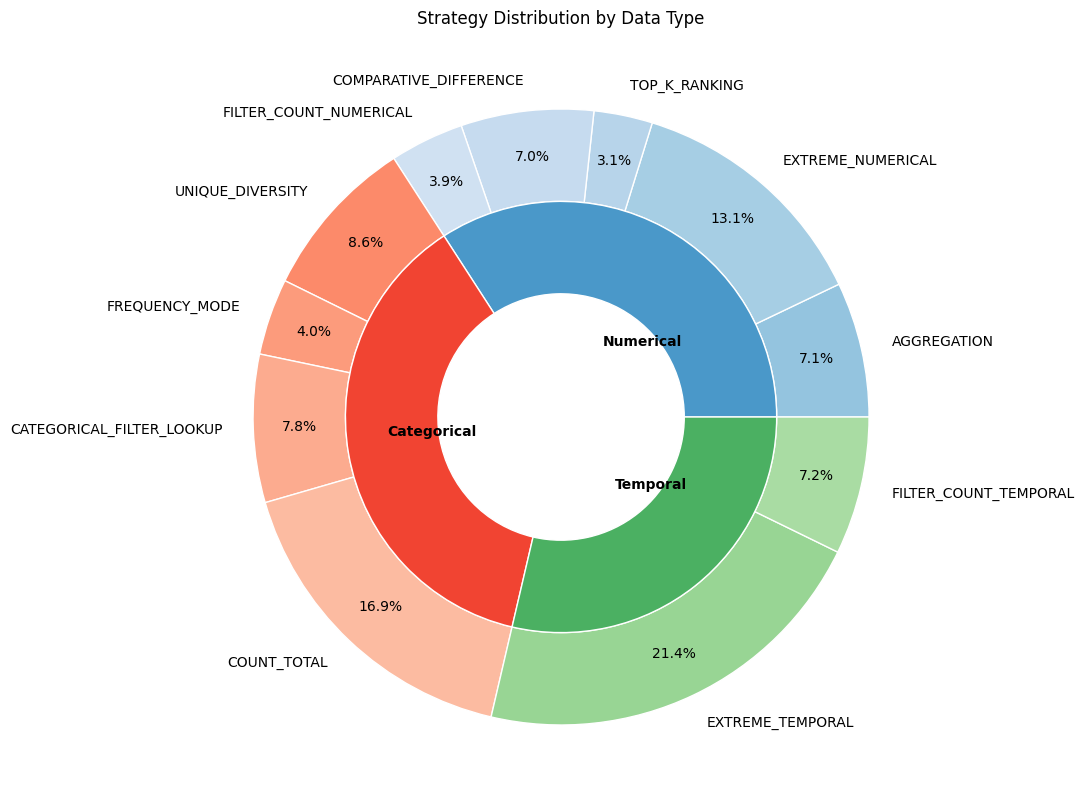

In [144]:
from knowledge_maze.create_dataset.create_questions.question_generation import TableSanitizer, StrategySelector, QuestionGenerator

sanitizer = TableSanitizer(group_constructor.valid_tables)
sanitizer.process_tables()

selector = StrategySelector(sanitizer.sanitized_tables)
selector.get_strategies()

generator = QuestionGenerator(selector.updated_data, 
                              strategy_definitions=load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
_ = await generator.generate_questions()

In [143]:
# EXTREME_NUMERICAL         : Success
# EXTREME_TEMPORAL          : Success
# COUNT_TOTAL               : Success
# UNIQUE_DIVERSITY          : Success
# CATEGORICAL_FILTER_LOOKUP : Faliure
# FILTER_COUNT_TEMPORAL     : Faliure
# FREQUENCY_MODE            :
# EXTREME_NUMERICAL         :
# AGGREGATION               :
# FILTER_COUNT_NUMERICAL    :
# TOP_K_RANKING             :
# COMPARATIVE_DIFFERENCE    :

import random
import pandas as pd

TARGET_STRATEGY = "FREQUENCY_MODE"
N = 5

matches = [
    sample
    for sample in generator.valid_results
    if sample.get("Selected strategy") == TARGET_STRATEGY
]

for sample in random.sample(matches, min(N, len(matches))):
    print(f"Group name: {sample['Group name']}")
    print(f"Strategy: {sample['Selected strategy']}")
    print(f"Question: {sample['Question']}")
    print(f"Wikipedia page: {sample['Wiki link']}")
    display(pd.DataFrame(sample['Relevant table data']))
    display(pd.DataFrame(sample['Full table data']))
    print("\n")

Group name: Distributors of Baahubali 2: The Conclusion
Strategy: FREQUENCY_MODE
Question: What is the most common language or set of languages distributed by the distributors of Baahubali 2: The Conclusion?
Wikipedia page: https://en.wikipedia.org/wiki/Baahubali_2:_The_Conclusion#Release


,Distributor,Languages
0,Great India Films,All
1,Sarigama Cinema,All
2,MSK Film Production,"Telugu, Tamil, Malayalam"
3,A. A. Films Pvt. Ltd.,Hindi
4,Hasini Entertainment,"Telugu, Tamil, Malayalam"
5,Phars Films Co LLC,"Telugu, Tamil, Malayalam"
6,Southern Star International,"Telugu, Tamil, Malayalam"
7,Gopi Krishna Movies,Hindi


,Distributor,Languages,Territories
0,Great India Films,All,USA and Canada
1,Sarigama Cinema,All,Europe and Ireland
2,MSK Film Production,"Telugu, Tamil, Malayalam","Malaysia, Singapore, Sri Lanka"
3,A. A. Films Pvt. Ltd.,Hindi,"Entire World except USA, Canada"
4,Hasini Entertainment,"Telugu, Tamil, Malayalam","UK, Ireland"
5,Phars Films Co LLC,"Telugu, Tamil, Malayalam",Middle East
6,Southern Star International,"Telugu, Tamil, Malayalam",Australia and New Zealand
7,Gopi Krishna Movies,Hindi,Nepal




Group name: Submachine guns of the Indonesian Army
Strategy: FREQUENCY_MODE
Question: What is the most common caliber used in submachine guns of the Indonesian Army?
Wikipedia page: https://en.wikipedia.org/wiki/List_of_equipment_of_the_Indonesian_Army#Small_arms


,Model,Caliber
0,PM2,9×19mm
1,MP9,9×19mm
2,K7,9×19mm
3,Uzi,9×19mm
4,MP5,9×19mm
5,P90,FN 5.7×28mm
6,MP7,4.6×30mm


...

,Year,Term
0,1834,1 year
1,1849,2 years
2,1897,4 years
3,1901,2 years
4,1905,4 years
5,1993,4 years
6,2008,4 years
7,2010,4 years


,Year,Term,Term limit,Years,Mayor(s) affected
0,1834,1 year,(no limit),(unlimited),all from Cornelius Van Wyck Lawrence to Caleb ...
1,1849,2 years,(no limit),(unlimited),all from Ambrose Kingsland to William L. Strong 1
2,1897,4 years,1 term,4 years,Robert A. Van Wyck
3,1901,2 years,(no limit),(unlimited),Seth Low and George B. McClellan Jr. 2
4,1905,4 years,(no limit),(unlimited),all from George B. McClellan Jr. 2 to David Di...
5,1993,4 years,2 terms,8 years,Rudy Giuliani 4
6,2008,4 years,3 terms,12 years,Michael Bloomberg 5 only 6
7,2010,4 years,2 terms,8 years,Bill de Blasio and his successors 6




Group name: Freelancing platforms in the gig economy
Strategy: FREQUENCY_MODE
Question: Which country is the most common base for freelancing platforms in the gig economy?
Wikipedia page: https://en.wikipedia.org/wiki/List_of_gig_economy_companies#List_of_gig_economy_companies


,Company,Based in
0,Fiverr,Israel
1,Airtasker,Australia
2,Amazon Mechanical Turk,United States
3,Toloka,United States
4,Figure Eight Inc.,United States
5,Freelancer.com,Australia
6,Upwork,United States
7,PeoplePerHour,United Kingdom
8,Toptal,United States
9,Hello Alfred,United States


,Company,Based in,Description
0,Fiverr,Israel,An online freelancing platform
1,Airtasker,Australia,An online marketplace for outsourcing tasks
2,Amazon Mechanical Turk,United States,An online crowdsourcing website for performing...
3,Toloka,United States,An online crowdsourcing website for performing...
4,Figure Eight Inc.,United States,An online work platform to complete tasks
5,Freelancer.com,Australia,An online freelancing platform
6,Upwork,United States,An online freelancing platform
7,PeoplePerHour,United Kingdom,An online freelancing platform
8,Toptal,United States,An online freelancing platform
9,Hello Alfred,United States,An online platform for completing tasks


In [145]:
from knowledge_maze.create_dataset.create_questions.question_validator import QuestionValidator

validator = QuestionValidator(load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))

ver = await validator.validate_samples(random.sample(generator.valid_results, 200))

Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/200 [00:00<?, ?it/s]


📊 VALIDATION SUMMARY
Total Samples:   200
✅ Approved:     183
❌ Rejected:     17
📈 Pass Rate:    91.5%
--------------------------------------------------

🔍 TOP REJECTION EXAMPLES:

1. Strategy: TOP_K_RANKING
   Question: Who were the top three goal scorers for Manchester City F.C. during the 1900–01 season based on the number of goals scored?
   Data: Scorers of the 1900–01 Manchester City F.C. season


,Scorer,"Scorer, Goals"
0,Joe Cassidy,None
1,Billie Gillespie,None
2,Billy Meredith,None
3,Fred Williams,None
4,Jimmy Ross,None
5,George Dougal,None
6,Billy Holmes,None
7,Jimmy Scotson,None
8,Davies,None
9,Bobby Moffatt,None


   🚩 Reason: The 'Scorer, Goals' column contains only 'None' values, making it impossible to determine the top three goal scorers. The strategy requires a numerical metric to rank entities, which is missing here.

2. Strategy: FILTER_COUNT_NUMERICAL
   Question: How many matches did the Brunei national rugby union team win against opponents with a win percentage greater than 0%?
   Data: Brunei national rugby union team match records


,Opponent,% Won
0,Cambodia,37.5 %
1,China,0%
2,Guam,0%
3,Indonesia,0%
4,Laos,40 %
5,Mongolia,0%
6,Philippines,0%
7,Singapore,0%


...

   🚩 Reason: The question is trivial. The strategy is CATEGORICAL_FILTER_LOOKUP, which means it should filter by a specific category and then either retrieve a value or count. The question asks for the number of times 'First Round' appears, but 'First Round' is present in every entry of the 'Round' column. This makes the question equivalent to asking for the total number of entries, which is a trivial count and does not effectively utilize the categorical filter as intended by the strategy. A non-trivial question would filter by a more specific round or combination of rounds that doesn't appear in every entry.

4. Strategy: EXTREME_NUMERICAL
   Question: Which racial or ethnic group had the lowest population in Cypress, California in 2020?
   Data: Racial and Ethnic Composition of Cypress, California (2020)


,Race / Ethnicity ( NH = Non-Hispanic ),"Race / Ethnicity ( NH = Non-Hispanic ), Pop 2020"
0,White alone (NH),None
1,Black or African American alone (NH),None
2,Native American or Alaska Native alone (NH),None
3,Asian alone (NH),None
4,Native Hawaiian or Pacific Islander alone (NH),None
5,Other race alone (NH),None
6,Mixed race or Multiracial (NH),None
7,Hispanic or Latino (any race),None


   🚩 Reason: The 'Pop 2020' column contains all null values, making it impossible to determine the lowest population. The question is unanswerable based on the provided data.

5. Strategy: CATEGORICAL_FILTER_LOOKUP
   Question: What was the result for Peter O'Toole in the Best Actor category at the Academy Awards for the film Goodbye, Mr. Chips?
   Data: Accolades for Goodbye, Mr. Chips (1969 film)


,Nominee(s),Result
0,Peter O'Toole,Nominated
1,Music and Lyrics by Leslie Bricusse Score Adap...,Nominated
2,Peter O'Toole,Won
3,Herbert Ross,Won
4,Peter O'Toole,Won
5,Siân Phillips,Nominated
6,Leslie Bricusse,Nominated
7,"Goodbye, Mr. Chips",4th Place
8,Peter O'Toole,Won
9,Peter O'Toole,2nd Place


   🚩 Reason: The question asks for the result for Peter O'Toole in the 'Best Actor category at the Academy Awards'. The provided table data does not contain information about categories (e.g., 'Best Actor') or specific award ceremonies (e.g., 'Academy Awards'). Therefore, the question is not answerable using only the provided data.



In [155]:
# EXTREME_NUMERICAL         : 
# EXTREME_TEMPORAL          : 
# COUNT_TOTAL               : 
# UNIQUE_DIVERSITY          : 
# CATEGORICAL_FILTER_LOOKUP : 
# FILTER_COUNT_TEMPORAL     : 
# FREQUENCY_MODE            : Success
# EXTREME_NUMERICAL         :
# AGGREGATION               : Partial - made a prompt fix for the scope of Top X in the aggragation. Still - No avg for some reason.
# FILTER_COUNT_NUMERICAL    :
# TOP_K_RANKING             : Success (need to set k to random somehow).
# COMPARATIVE_DIFFERENCE    :

import random
import pandas as pd

TARGET_STRATEGY = "AGGREGATION"
N = 5

matches = [
    sample
    for sample in validator.approved_data
    if sample.get("Selected strategy") == TARGET_STRATEGY
]

for sample in random.sample(matches, min(N, len(matches))):
    print(f"Group name: {sample['Group name']}")
    print(f"Strategy: {sample['Selected strategy']}")
    print(f"Question: {sample['Question']}")
    print(f"Wikipedia page: {sample['Wiki link']}")
    display(pd.DataFrame(sample['Relevant table data']))
    # display(pd.DataFrame(sample['Full table data']))
    print("\n")

Group name: Champions in Players Series Snooker
Strategy: AGGREGATION
Question: What is the total number of championships won by players in the Champions in Players Series Snooker?
Wikipedia page: https://en.wikipedia.org/wiki/Players_Series#Statistics


,Player,Total
0,Neil Robertson,5
1,Ronnie O'Sullivan,4
2,Judd Trump,3
3,Shaun Murphy,2
4,Mark Allen,2
5,John Higgins,2
6,Stephen Maguire,1
7,Mark Williams,1
8,Kyren Wilson,1




Group name: Former Lynx Air Fleet
Strategy: AGGREGATION
Question: What is the total number of aircraft in the former Lynx Air fleet?
Wikipedia page: https://en.wikipedia.org/wiki/Lynx_Air#Fleet


,Aircraft,Total
0,Boeing 737-700,7
1,Boeing 737-800,1
2,Boeing 737-800,1
3,De Havilland Canada DHC-6 Twin Otter,2
4,Piper PA-30 Twin Comanche,1
5,Airbus A320-200,1




Group name: Men's standings in the 1997–98 FIS Cross-Country World Cup
Strategy: AGGREGATION
Question: What is the total number of points accumulated by all competitors in the **1997–98 FIS Cross-Country World Cup**?
Wikipedia page: https://en.wikipedia.org/wiki/1997–98_FIS_Cross-Country_World_Cup#Men's_standings


,after all 12 events,Points
0,Thomas Alsgaard,790
1,Bjørn Dæhlie,678
2,Vladimir Smirnov,431
3,Mikhail Botvinov,330
4,Jari Isometsä,316
5,Fulvio Valbusa,310
6,Mika Myllylä,308
7,Erling Jevne,292
8,Silvio Fauner,273
9,Mathias Fredriksson,268




Group name: Growth of British railways
Strategy: AGGREGATION
Question: What is the total number of miles of British railways constructed by 1860?
Wikipedia page: https://en.wikipedia.org/wiki/History_of_rail_transport#History_by_country


,Year,Total miles
0,1830,98
1,1835,338
2,1840,1498
3,1845,2441
4,1850,6621
5,1855,8280
6,1860,10433




Group name: Highest-grossing Hong Kong films of 2019
Strategy: AGGREGATION
Question: What is the total domestic gross of the highest-grossing films in Hong Kong for 2019?
Wikipedia page: https://en.wikipedia.org/wiki/List_of_Hong_Kong_films_of_2019#Box_office


,Title,Domestic gross
0,Integrity,"HK$30,986,111"
1,Ip Man 4: The Finale,"HK$28,983,160"
2,The White Storm 2: Drug Lords,"HK$24,373,233"
3,Still Human,"HK$19,201,830"
4,P Storm,"HK$17,514,387"
